In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

BASE_DIR = os.path.abspath(".")
DATA_DIR = os.path.join(BASE_DIR, "data", "dogs_cats_subset")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
MODELS_DIR = os.path.join(BASE_DIR, "models")

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.21.0


In [ ]:
with open(os.path.join(RESULTS_DIR, "task3_dogs_cats_summary.json")) as f:
    results = json.load(f)

print("Завантажено результати експериментів:", list(results.keys()))

Завантажено результати експериментів: ['3.1_vgg16_no_aug', '3.2_vgg16_with_aug', '3.3_vgg16_finetuned', '3.4_resnet50']


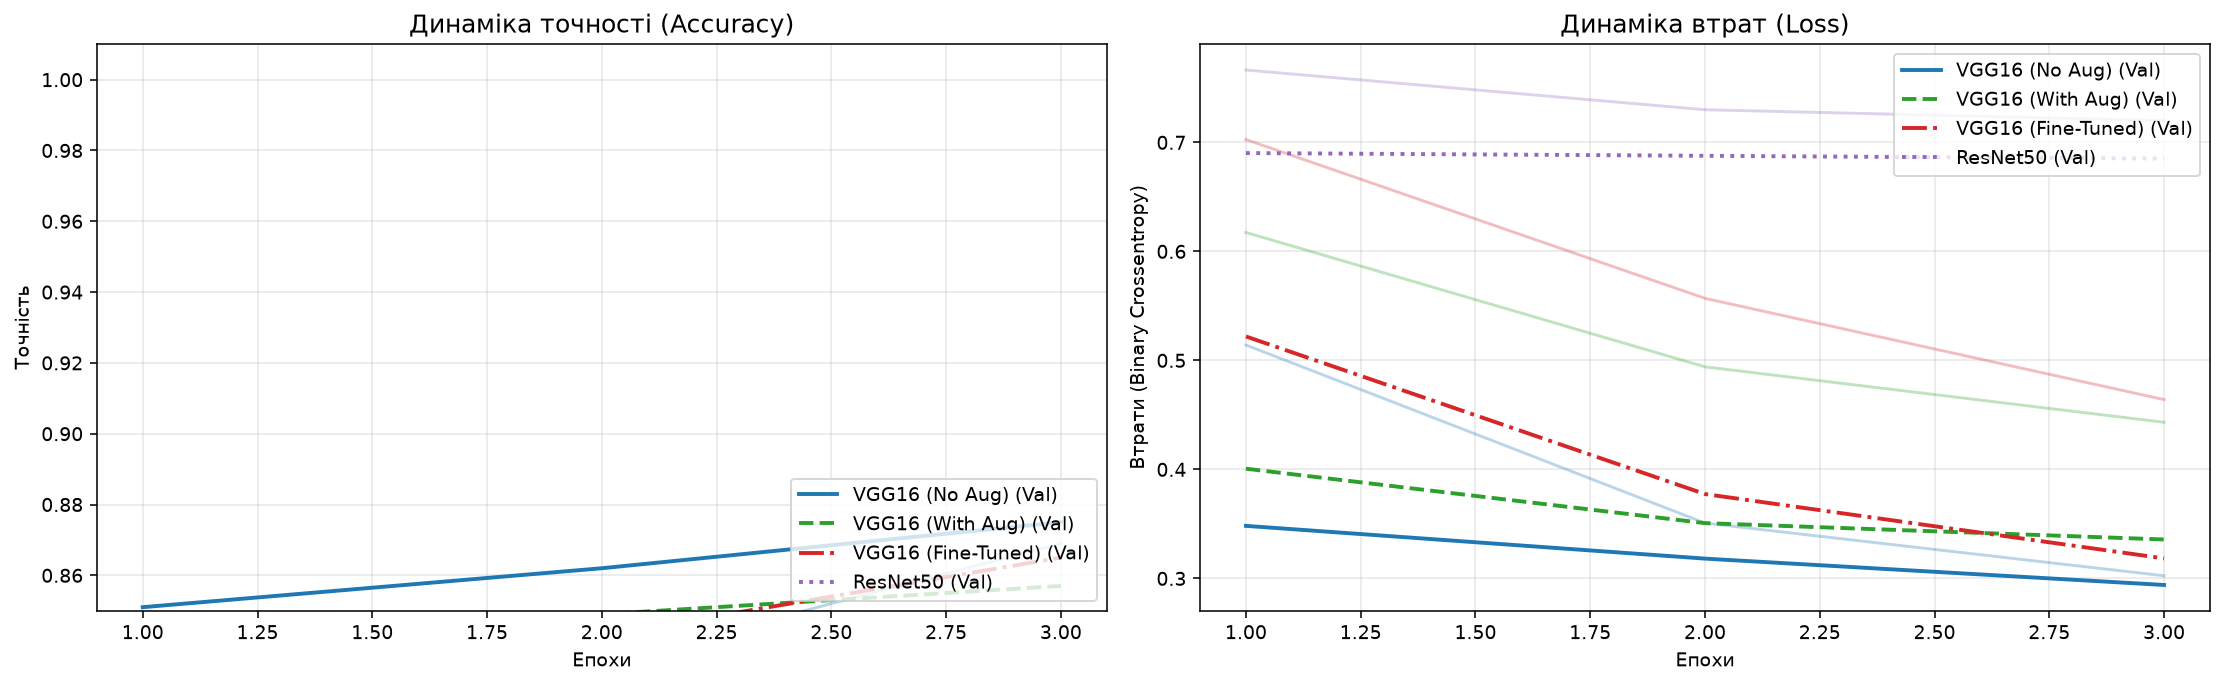

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

configs = [
    ("3.1_vgg16_no_aug", "VGG16 (No Aug)", "tab:blue", "-"),
    ("3.2_vgg16_with_aug", "VGG16 (With Aug)", "tab:green", "--"),
    ("3.3_vgg16_finetuned", "VGG16 (Fine-Tuned)", "tab:red", "-."),
    ("3.4_resnet50", "ResNet50", "tab:purple", ":")
]

for key, label, color, ls in configs:
    hist = results[key]["history"]
    epochs = range(1, len(hist["accuracy"]) + 1)
    axes[0].plot(epochs, hist["val_accuracy"], label=f"{label} (Val)", color=color, linestyle=ls, linewidth=2)
    axes[0].plot(epochs, hist["accuracy"], color=color, alpha=0.3)

axes[0].set_title("Динаміка точності (Accuracy)", fontsize=13)
axes[0].set_xlabel("Епохи")
axes[0].set_ylabel("Точність")
axes[0].set_ylim(0.85, 1.01)
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="lower right")

for key, label, color, ls in configs:
    hist = results[key]["history"]
    epochs = range(1, len(hist["loss"]) + 1)
    axes[1].plot(epochs, hist["val_loss"], label=f"{label} (Val)", color=color, linestyle=ls, linewidth=2)
    axes[1].plot(epochs, hist["loss"], color=color, alpha=0.3)

axes[1].set_title("Динаміка втрат (Loss)", fontsize=13)
axes[1].set_xlabel("Епохи")
axes[1].set_ylabel("Втрати (Binary Crossentropy)")
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

In [4]:
print(f"{'Модель':<25} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'ROC-AUC':<10} | {'External Acc':<12}")
print("-" * 105)
for key, label, _, _ in configs:
    t = results[key]["test"]
    ext = results[key]["external"]["external_accuracy"]
    print(f"{label:<25} | {t['accuracy']*100:>8.2f}% | {t['precision']*100:>8.2f}% | {t['recall']*100:>8.2f}% | {t['f1']*100:>8.2f}% | {t['roc_auc']:>9.4f} | {ext*100:>10.2f}%")

Модель                    | Accuracy   | Precision  | Recall     | F1-Score   | ROC-AUC    | External Acc
---------------------------------------------------------------------------------------------------------
VGG16 (No Aug)            |    89.30% |    94.36% |    83.60% |    88.65% |    0.9654 |      80.00%
VGG16 (With Aug)          |    87.10% |    93.24% |    80.00% |    86.11% |    0.9592 |      70.00%
VGG16 (Fine-Tuned)        |    88.40% |    84.78% |    93.60% |    88.97% |    0.9592 |      90.00%
ResNet50                  |    54.40% |    52.56% |    90.20% |    66.42% |    0.6093 |      50.00%


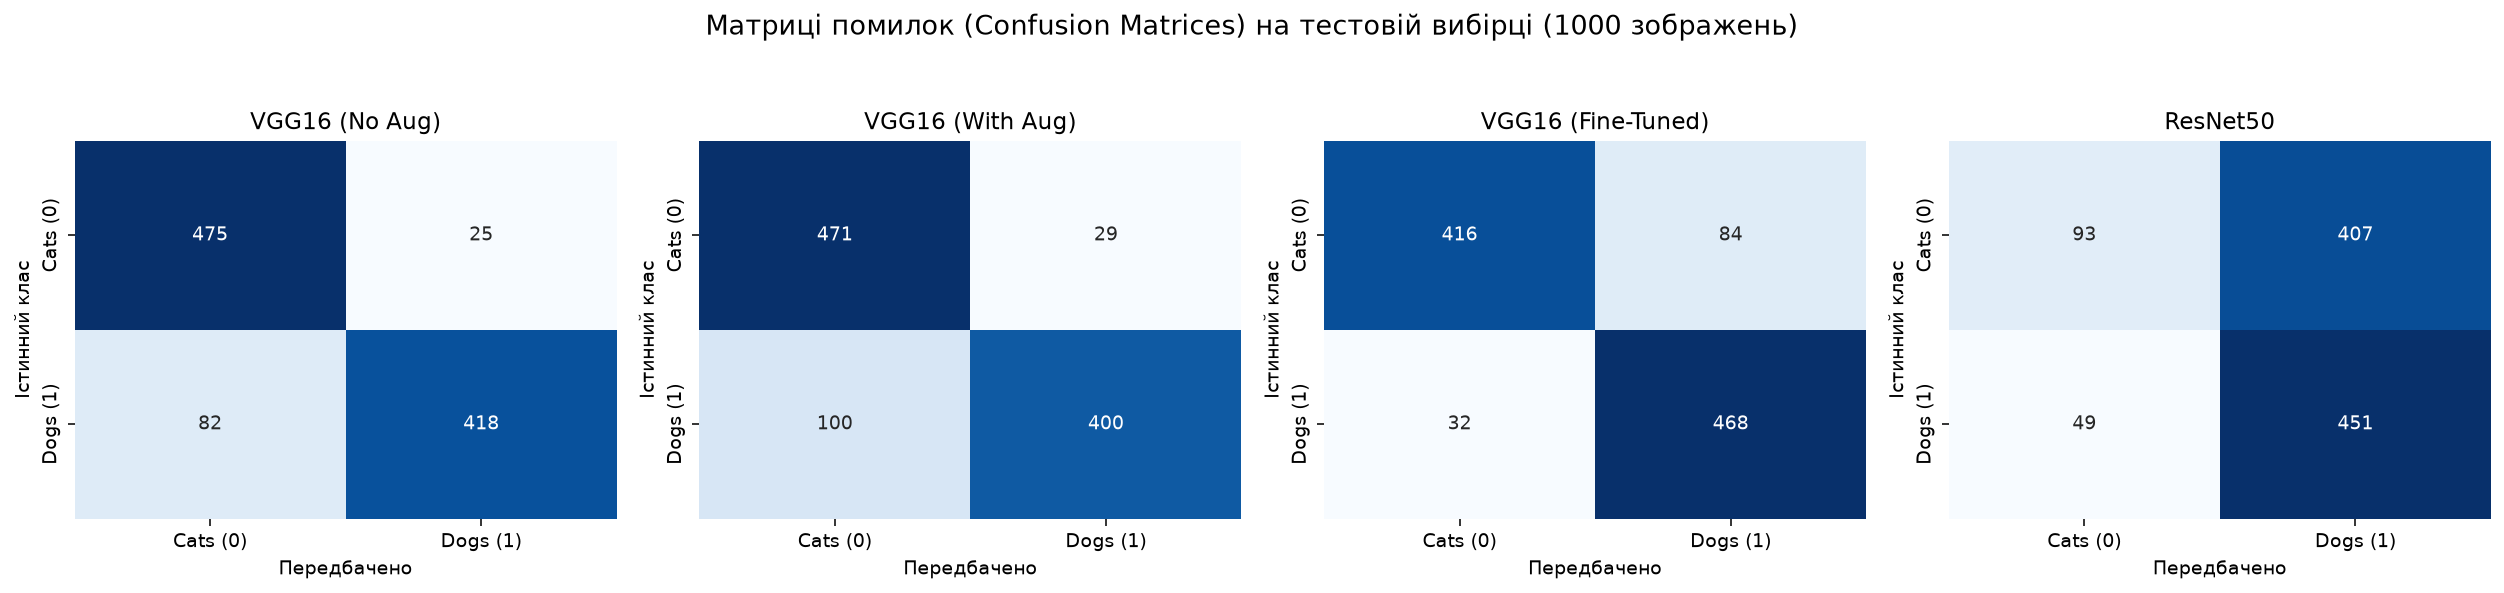

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for idx, (key, label, _, _) in enumerate(configs):
    cm = np.array(results[key]["test"]["confusion_matrix"])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Cats (0)', 'Dogs (1)'], yticklabels=['Cats (0)', 'Dogs (1)'])
    axes[idx].set_title(label, fontsize=12)
    axes[idx].set_xlabel("Передбачено")
    axes[idx].set_ylabel("Істинний клас")

plt.suptitle("Матриці помилок (Confusion Matrices) на тестовій вибірці (1000 зображень)", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()